In [174]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

## Profile the data

In [175]:
## Loading the data and combined the data with country column
us_df=pd.read_csv('data/USvideos.csv')
in_df=pd.read_csv('data/INvideos.csv')
gb_df=pd.read_csv('data/GBvideos.csv')
cat_df=pd.read_csv('data/categories.csv')

us_df['country']='US'
in_df['country']='IN'
gb_df['country']='GB'

combined_df=pd.concat([us_df,in_df,gb_df])


#Shape of combined dataset of three countries
print(f'Shape of Combined Dataset:\n {combined_df.shape}')
print()
#dtypes of every columns in the dataset
print(f'Dtypes of Columns in combined dataset:\n {combined_df.info()}')
print()

#Checking missing Values and fill with appropriate values and calculate its percentage
missing_sum=combined_df.isna().sum()
print(f'Checking the null values in the Dataset:\n {missing_sum}')
print()
#likes and comment count filled with 0 and in description filled with Unknown as a placeholder
num_cols=combined_df.select_dtypes(['int64','float64']).columns
combined_df[num_cols]=combined_df[num_cols].fillna(0)
combined_df['description']=combined_df['description'].fillna('Unknown')

#Missing Percent
missing_percent=(missing_sum/len(combined_df))* 100
print(f'Missing Percentage of this combined dataset:\n {missing_percent}')
print()

#After Checking is there any null values
print(f'Checking the null values after filling with  appropriate values:\n {combined_df.isna().sum()}')
print()



#Checking the duplicates rows and drop the duplicates rows
print(f'No. of Duplicates in the dataset: {combined_df.duplicated().sum()}')
print()
combined_df=combined_df.drop_duplicates()
print(f'No. of Duplicates in the dataset after droping: {combined_df.duplicated().sum()}')
print()

combined_df=pd.merge(combined_df,cat_df,on='category_id',how='inner')



#Viewing the videos which are removed or gets videeo error
video_removed_or_error=combined_df[combined_df['video_error_or_removed']==True]

print(f'Videos gets removed or got error: \n{video_removed_or_error[['video_id','country','title']]}')
print()
print(f'No. of videos gets error or removed: {len(video_removed_or_error)}')



#Converting DAte columns to datetime format
combined_df['trending_date'] = pd.to_datetime(combined_df['trending_date'], format='%y.%d.%m').dt.tz_localize(None)
combined_df['publish_time'] = pd.to_datetime(combined_df['publish_time']).dt.tz_localize(None)


Shape of Combined Dataset:
 (46230, 17)

<class 'pandas.core.frame.DataFrame'>
Index: 46230 entries, 0 to 15074
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   video_id                46230 non-null  object 
 1   trending_date           46230 non-null  object 
 2   title                   46230 non-null  object 
 3   channel_title           46230 non-null  object 
 4   category_id             46230 non-null  int64  
 5   publish_time            46230 non-null  object 
 6   tags                    46230 non-null  object 
 7   views                   46230 non-null  int64  
 8   likes                   46218 non-null  float64
 9   dislikes                46230 non-null  int64  
 10  comment_count           46194 non-null  float64
 11  thumbnail_link          46230 non-null  object 
 12  comments_disabled       46230 non-null  bool   
 13  ratings_disabled        46230 non-null  bool   
 14  vi

##  Visualizing Data Using Matplotlib


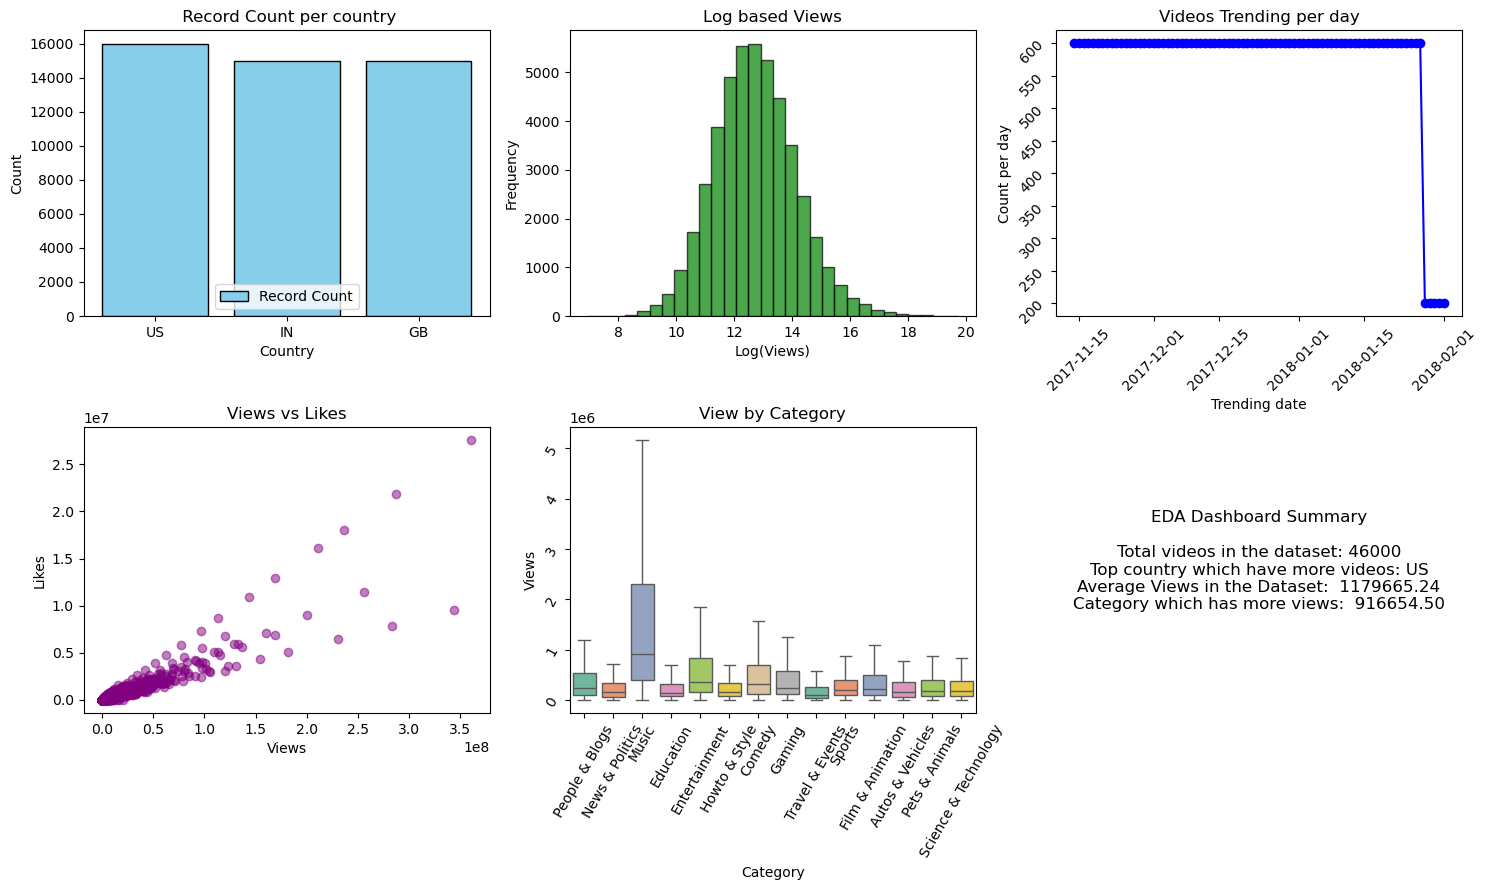

In [176]:
#Using bar chart analyzing categorical data
fig,axes=plt.subplots(2,3,figsize=(15,9))
country_counts=combined_df['country'].value_counts()
axes[0,0].bar(country_counts.index,country_counts.values,label='Record Count',color="skyblue",edgecolor='black')
axes[0,0].set_title(' Record Count per country')
axes[0,0].set_xlabel('Country')
axes[0,0].set_ylabel('Count')
axes[0,0].legend(['Record Count'])






#Using Histogram chart analzying numerical data
log_based_views=np.log(combined_df['views'])
axes[0,1].hist(log_based_views,bins=30,color='green',alpha=0.7,edgecolor='black')
axes[0,1].set_title('Log based Views')
axes[0,1].set_xlabel('Log(Views)')
axes[0,1].set_ylabel('Frequency')
# plt.legend()



#Using line chart analyznumber videos trending per day


videos_trend_per_day=combined_df.groupby('trending_date').size()
axes[0,2].plot(videos_trend_per_day.index,videos_trend_per_day.values,color='blue',linestyle='-',marker='o')
axes[0,2].set_title('Videos Trending per day')
axes[0,2].set_xlabel('Trending date')
axes[0,2].set_ylabel('Count per day')
axes[0,2].tick_params(rotation=45)




#Using Scatter plot to compare numerical data vs numerical data

axes[1,0].scatter(x=combined_df['views'],y=combined_df['likes'],alpha=0.5,color='purple')
axes[1,0].set_title('Views vs Likes')
axes[1,0].set_xlabel('Views')
axes[1,0].set_ylabel('Likes')








#Using Box plot analyze how many view got for each category

sns.boxplot(x='category_name',y='views',data=combined_df,showfliers=False,palette='Set2',ax=axes[1,1],hue='category_name')
axes[1,1].set_title('View by Category')
axes[1,1].set_xlabel('Category')
axes[1,1].set_ylabel('Views')
axes[1,1].tick_params(rotation=60)


#Summary
total_videos=len(combined_df)
top_country=combined_df['country'].value_counts().idxmax()
avg_views=combined_df['views'].mean()
top_category_by_views=combined_df.groupby('category_name')['views'].median().max()

summary_text=( f"EDA Dashboard Summary\n\n"
               f'Total videos in the dataset: {total_videos}\n'
             f'Top country which have more videos: {top_country}\n'
             f'Average Views in the Dataset: {avg_views: .2f}\n'
             f'Category which has more views: {top_category_by_views: .2f}\n'   
)


axes[1,2].axis("off")
axes[1,2].text(0.5, 0.5, summary_text, ha="center", va="center", fontsize=12)
plt.tight_layout()
plt.show()





## Interactive Charts using Plotly

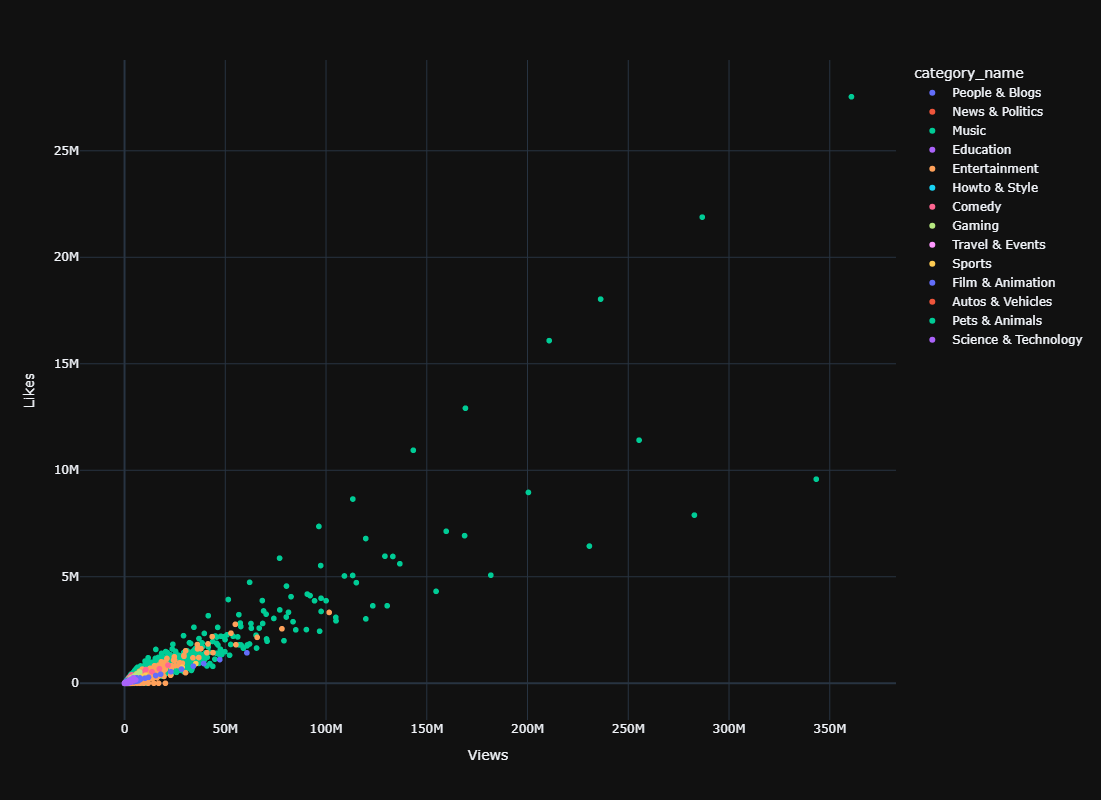

In [177]:

#Interactive chart based scatter plot on views and likes and differentiate by category name
fig1=px.scatter(combined_df,x='views',y='likes',hover_name='title',color='category_name')


fig1.update_layout(
    title_font_size=20,
    xaxis_title='Views',
    yaxis_title='Likes',
    template='plotly_dark',
    height=800,
    width=800
)
fig1.show()


**Interpretation:**
- This plot shows the relationship between views and likes across different categories.
- Generally, videos with more views tend to receive more likes, although the strength of
this relationship varies by category.
- The scatter plot is appropriate here because both
variables are numeric, and it clearly illustrates their correlation.

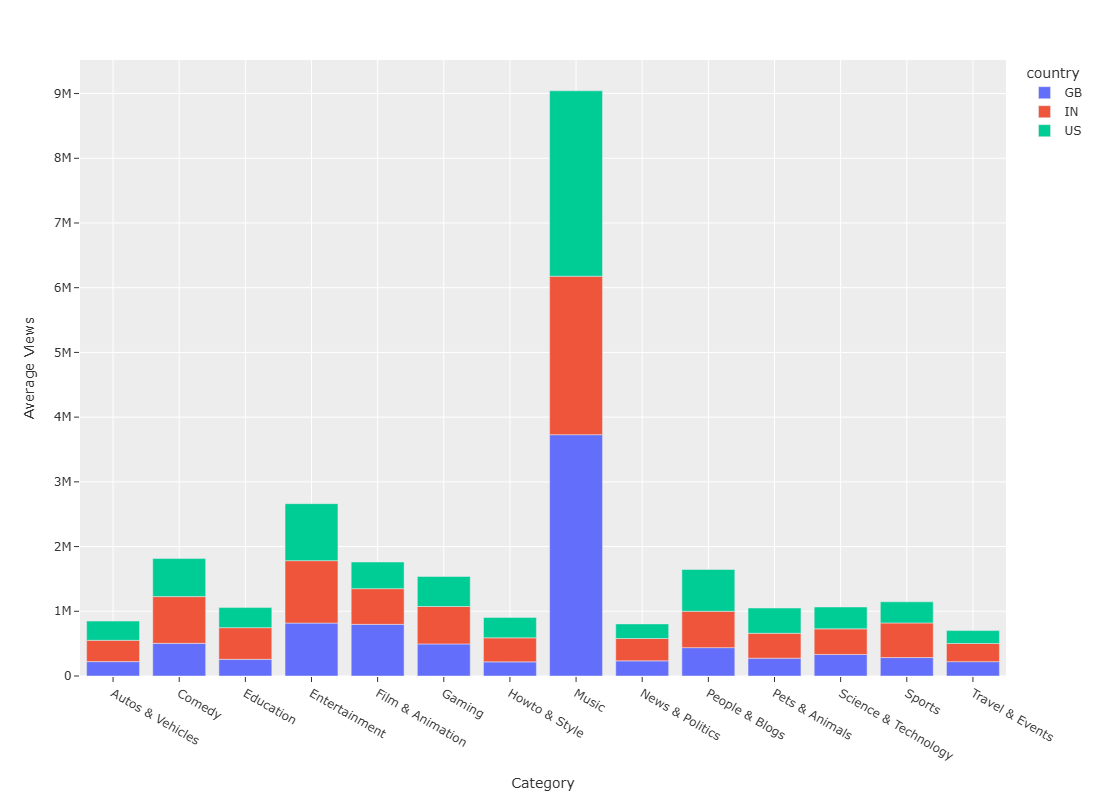

In [178]:
#Interactive chart based on bar chart  on average views per category across countries
avg_views_per_category=combined_df.groupby(['category_name','country'])['views'].mean().reset_index()

fig2=px.bar(avg_views_per_category,x='category_name',y='views',color='country')
fig2.update_layout(
    title_font_size=20,
    xaxis_title='Category',
    yaxis_title='Average Views',
    template='ggplot2',
    height=800,
    width=800
)
fig2.show()

### 📊 Interpretation:
- This plot shows the average view based on category across all the countries.
- This plot based on the Average views on categories differs by countries, which some categories content gives higher views based on the video categories like Music, Entertainment etc.,
- This plot shows the relationship between the categories and Average views.

## Distributions and Outliers

In [179]:
#Calculating Mean, Median and Mode of Views and likes column
views_stats=combined_df['views'].agg(['mean','median']).round(2)
views_mode=combined_df['views'].mode()[0]
print(f""" {views_stats},
mode: {views_mode}
""")


likes_stats=combined_df['likes'].agg(['mean','median'])
likes_mode=combined_df['likes'].mode()
print(f""" {likes_stats},
mode: {likes_mode}
""")

#Checking skewness of views and likes
views_skew=combined_df['views'].skew()
likes_skew=combined_df['likes'].skew()

print(f'View Skewness: {views_skew}, Like Skewness: {likes_skew}')

 mean      1179665.24
median     318389.00
Name: views, dtype: float64,
mode: 16000

 mean      45838.71363
median    10204.00000
Name: likes, dtype: float64,
mode: 0    0.0
Name: likes, dtype: float64

View Skewness: 27.956058457653512, Like Skewness: 44.521951477843984


- Here for both Views and Likes have right skewness becuase the mean, median and mode are in this form mean > median > mode
- Also using ".skew()" we also got postive values
- According to the values we can determine the data is right skewed Data

In [180]:
#Apply IQR Rule for Outliers
views_Q1=combined_df['views'].quantile(0.25)
views_Q3=combined_df['views'].quantile(0.75)
views_iqr=views_Q3-views_Q1
lower_bound_views=views_Q1-1.5 * views_iqr
upper_bound_views=views_Q3+1.5 * views_iqr
outliers_views = combined_df[(combined_df['views'] <  lower_bound_views )| (combined_df['views'] > upper_bound_views)] 
len(outliers_views)



likes_Q1=combined_df['likes'].quantile(0.25)
likes_Q3=combined_df['likes'].quantile(0.75)
likes_iqr=views_Q3-views_Q1
lower_bound_likes=likes_Q1-1.5 * likes_iqr
upper_bound_likes=likes_Q3+1.5 * likes_iqr
outliers_likes = combined_df[(combined_df['likes'] <  lower_bound_likes )| (combined_df['likes'] > upper_bound_likes)] 
len(outliers_likes)


189

- Number of Outliers in Views: 5079
- Numberof Outlier in Likes: 189
- We can keep the Outliers for anlysis beacuse the views and likes count is important for trending analysis for all the features like Engagement scores
  

## Correlation

In [181]:
correlation_matrix=combined_df[num_cols].corr()

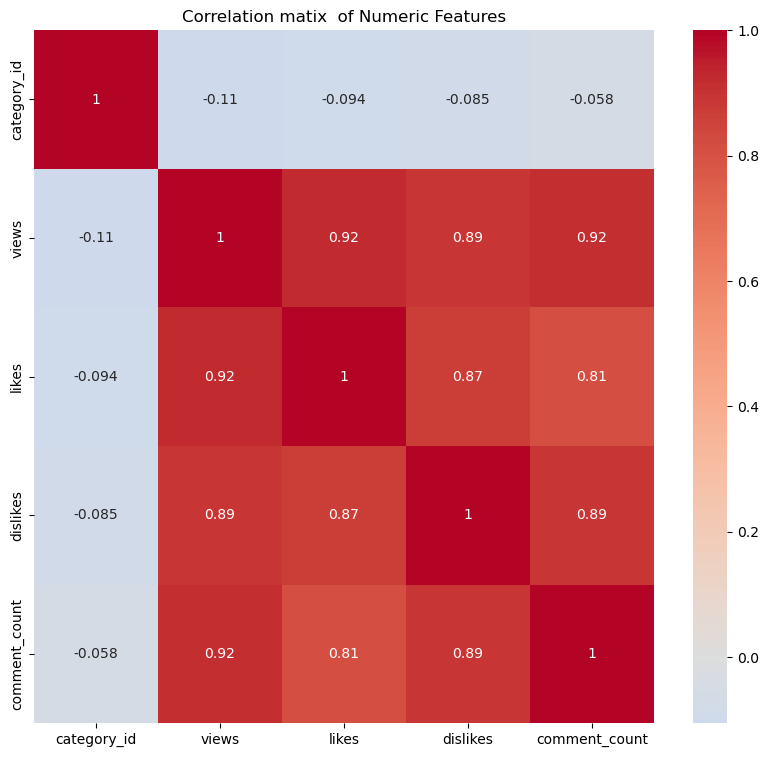

In [182]:
plt.figure(figsize=(10,9))
sns.heatmap(correlation_matrix,annot=True,cmap='coolwarm',center=0)
plt.title('Correlation matix  of Numeric Features')
plt.show()

- We can use the heatmap to see the relationship between numerical features.  
- Here, we can observe how views and likes are related to each other.  
- The correlation score between two features shows how strongly they influence each other; if it is close to 1, they are strongly related.  
- If it is below 0, it means they have little or no relationship.  
- In this heatmap, apart from category_id, the other features are related to each other.  
- Likes do not cause views, because without views there cannot be likes. Therefore, the views feature strongly influences other features except category_id.


## Funnel analysis

In [183]:
#Number of videos ever trended
stage1=combined_df['video_id'].nunique()

#videos which are higher views than median views
videos_peak_views=combined_df.groupby('video_id')['views'].max()
median_peak=videos_peak_views.median()
stage2=(videos_peak_views > median_peak).sum()


#Top 90 percentile of videos with pe
top_90_percentile_views=videos_peak_views.quantile(0.9)
stage3=(videos_peak_views > top_90_percentile_views).sum()

#Videos with 1000+ comments
videos_with_comments=combined_df.groupby('video_id')['comment_count'].max()
stage4=(videos_with_comments >= 1000).sum()

### Calculate the Converstion rate

In [184]:
conv1=(stage2/stage1) * 100
conv2=(stage3/stage2) * 100
conv3=(stage4/stage3) * 100

print(f'Conversion rate 1: {conv1}, Conversion rate 2: {conv2}, Conversation rate 3: {conv3}')

Conversion rate 1: 49.99659840805497, Conversion rate 2: 20.002721458701863, Conversation rate 3: 486.8707482993197


## Retention-style analysis (trending lifespan)

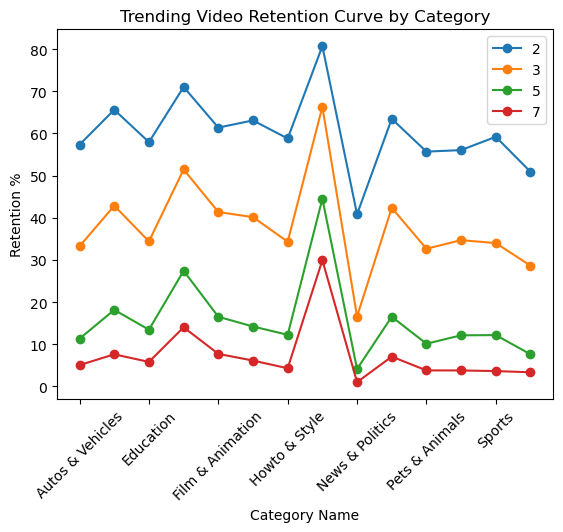

In [185]:
combined_df['day_index'] = combined_df.groupby('video_id')['trending_date'].rank(method='dense').astype('int')

#Checking video which are trending in Day 2,3,5,7
def retention_check(df:pd.DataFrame,col: str):
    check_days=[2,3,5,7]
    result={}
    for group,sub in df.groupby(col):
        total_videos=sub['video_id'].nunique()
        retention={}
        for day in check_days:
            retained = sub[sub['day_index'] == day]['video_id'].nunique()
            retention[day] = retained / total_videos * 100
        result[group]=retention
    return pd.DataFrame(result)

#Category based Rention Curve
category_retention = retention_check(combined_df,'category_name')
category_retention.T.plot(marker='o')
plt.title('Trending Video Retention Curve by Category')
plt.xlabel('Category Name')
plt.ylabel('Retention %')
plt.xticks(rotation=45)
plt.legend()
plt.show()

### 📊 Interpretation
- **Howto & Style** category videos have a strong retention period. On **Day 2**, retention peaks around **80%**, and by **Day 7** it remains at about **30%**.  
- **Education** and **Film & Animation** also maintain higher retention compared to other categories. They show consistent audience interest and sustain a decent retention rate over time.  
- **News & Politics** category videos have much lower retention. On **Day 2**, retention falls below **50%**, and by **Day 7** it drops to around **0–10%**, reflecting the short‑lived nature of topical content.  
- **Pets & Animals** and **Sports** categories also show lower retention. These videos attract limited audiences and tend to fade quickly from the trending list.  


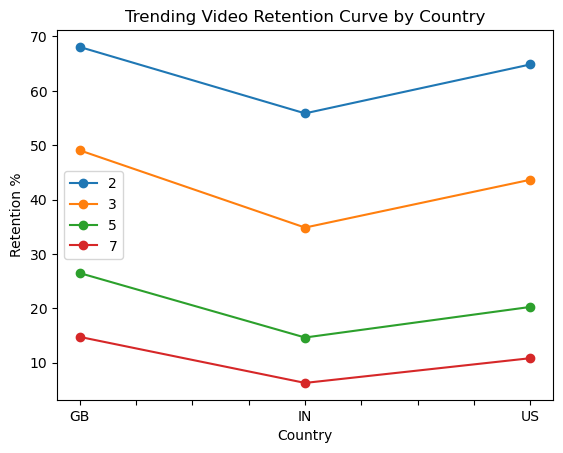

In [186]:

#Country based Retention Curve
country_retention = retention_check(combined_df,'country')
country_retention.T.plot(marker='o')
plt.title('Trending Video Retention Curve by Country')
plt.xlabel('Country')
plt.ylabel('Retention %')
plt.legend()

plt.show()

### 📊 Interpretation
- **Country GB** maintains high retention across all days. On **Day 2**, it records around **68–70%**, and still holds the highest retention by **Day 7**. This shows that audiences in GB have strong viewer consistency and a slower drop‑off rate.  
- **Country US** maintains moderate retention across all days. On **Day 2**, retention is around **60–70%**, but by **Day 7** it falls to **10–15%**, indicating that videos trend for a few days before dropping sharply.  
- **Country IN** shows lower retention across all days. On **Day 2**, retention is around **58–60%**, and by **Day 7** it drops below **10%**, suggesting that videos trend quickly but lose popularity faster.  


## Cohort view

In [187]:
#Taking the videos which it gets first treding date
first_trend=combined_df.groupby('video_id')['trending_date'].min().reset_index()
first_trend.rename(columns={'trending_date': "First  trending Date "},inplace=True)


#Merging first trend data to Combined Dataset
combined_df=combined_df.merge(first_trend,on='video_id',how='left')

In [188]:


#Creating a Column in which the videos get trended Week
combined_df['Trended_week']=combined_df['trending_date'].dt.to_period('W')

#calculating the lifespan the videos on trending
video_lifespan=combined_df.groupby('video_id')['trending_date'].agg(['min','max']).reset_index()
video_lifespan['lifespan_days']=(video_lifespan['max']-video_lifespan['min']).dt.days + 1


video_lifespan=video_lifespan.merge(first_trend[['video_id','First  trending Date ']],on='video_id',how='inner')
video_lifespan['cohort month']=video_lifespan['First  trending Date '].dt.to_period('W')

cohort_lifespan=video_lifespan.groupby('cohort month')['lifespan_days'].mean()
print(cohort_lifespan)

cohort month
2017-11-13/2017-11-19    4.127929
2017-11-20/2017-11-26    4.240842
2017-11-27/2017-12-03    4.202572
2017-12-04/2017-12-10    3.633466
2017-12-11/2017-12-17    3.111551
2017-12-18/2017-12-24    3.184290
2017-12-25/2017-12-31    3.150825
2018-01-01/2018-01-07    3.121662
2018-01-08/2018-01-14    3.144330
2018-01-15/2018-01-21    3.021196
2018-01-22/2018-01-28    2.321906
2018-01-29/2018-02-04    1.685039
Freq: W-SUN, Name: lifespan_days, dtype: float64


### **Interpretation**
- In November, the average lifespan ranges between **4.1–4.3 days**. We can interpret that videos trended for several days during this month.  
- In December, the average lifespan ranges between **3.1–3.7 days**. The average lifespan decreased compared to November, which suggests that more videos trended in December.  
- In January, the average lifespan ranges between **1.5–3.2 days**. The average lifespan is lower compared to November and December, indicating that more videos trended in January than in the other two months.  


## Content strategy briefing

### 📊 Category Insights
- **Music** category records dominate trending, with the highest views, likes, and comment counts compared to all other categories.  
- **Entertainment** category records rank second to Music in views, likes, and comments, outperforming the rest of the categories.  
- **Travel & Events** category records have the lowest trending presence, with significantly fewer views, likes, and comments than other categories.  

### ⏱️ How Quickly Videos Reach Trending
- Most videos appear on the trending list **within 2–4 days of upload**.  
- **Music and Entertainment** videos usually reach trending faster, and their lifespan can sometimes be longer due to strong engagement.  
- **News & Politics** and **Sports** videos may reach trending quickly, but their lifespan is short because the content is time‑sensitive.  
- **How‑to & Style** and **Education** videos take a little longer to reach trending, but once they do, they can remain visible for up to **7 days**, showing stronger retention.  

### 🌍 How Countries Differ
- **GB**: Retention is the strongest. On Day 2, videos hold around **68–70%**, and by Day 7 they still hold **10–20%**, the highest among all countries.  
- **US**: Retention is moderate. On Day 2, videos hold **60–70%**, and by Day 7 they drop to **10–15%**, considered a moderate score compared to other countries.  
- **IN**: Retention is the lowest. On Day 2, videos hold **58–60%**, but by Day 7 they fall below **10%**, making India the lowest in retention among the countries.  

